# Code for creating offline SuperdropNet timeseries
In the paper this corresponds to
- Figure 1
- FIgure S2

In [ ]:
import torch
import numpy as np
import xarray as xr
import seaborn as sns
from matplotlib import pyplot as plt

In [2]:
sns.set_context("notebook")

In [4]:
def superdropnet_idealised(superdropnet_path, moments_in =[0.0004, 1e8, 1e-7, 1e4] , loops=100, apply_thresh=True):
    snet_alpha = torch.jit.load(superdropnet_path)

    moments_in_np = np.zeros((1,4))
    moments_in_np[0,:] = moments_in

    moments_in = torch.from_numpy(moments_in_np).type(torch.float).unsqueeze(1)

    moments_out = torch.zeros((loops+1,1,4))
    moments_out[0,:,:] = moments_in

    for i in range(loops) :
        moments_out[i+1] = snet_alpha(moments_out[i].unsqueeze(0))
        # these threshold are applied in the ICON code at the end of the microphysics call to keep cloud and rain drop sizes contained.
        if apply_thresh :
            moments_out[i+1,0,1] = np.clip(moments_out[i+1,0,1], a_max=moments_out[i+1,0,0]/4.2e-15, a_min=moments_out[i+1,0,0]/2.6e-10)
            moments_out[i+1,0,3] = np.clip(moments_out[i+1,0,3], a_max=moments_out[i+1,0,2]/2.6e-10, a_min=moments_out[i+1,0,2]/6.5e-5)
    return moments_out.numpy()

In [5]:
def calc_qnc_from_r(r,qc) :
    rho = 1000.
    m_one_drop = rho * np.pi * (4./3.) * r**3
    return qc / m_one_drop

In [6]:
model = 'superdropnet_final_sharma2025.pt'
model_60s = 'superdropnet_final_sharma2025_60s.pt'
model_unconstrained = 'superdropnet_final_no_constraints.pt'

# 50-member ensemble over different intitial conditions

There are some conditions, with high qc and high qnc, where cloud to rain transition takes a lot of time. In these cases not all cloud water is converted to rain water, maybe because the transition happens to quickly: the peak of the rain number is reached early, the network thinks the cluod to rain transition is done only does rain drop growth...make sense?

Without contraints, even more cloud water is left over (or converted back from rain water!)

The network with the constraints has learned to generalise the cloud-to-rain transition beyond the training data range in principle, but has not learned to transfor all cloud water to rain water. Within the training data range this problem also occurs but to a much lesser degree.

In [7]:
ens = 50
qc = np.linspace(0.01e-3,5e-3,ens)
r = np.linspace(5e-6,20e-6,ens)
#qnc = np.linspace(3e8,1e9,ens)
qr = np.linspace(1e-13, 1e-13, ens)
qnr = np.linspace(1e3, 1e3, ens)

np.random.shuffle(qc)
np.random.shuffle(r)

qnc=calc_qnc_from_r(r, qc)

loops = 250

moments_3x20_ens = np.zeros((ens, loops*3+1, 1, 4))
moments_1x60_ens = np.zeros((ens, loops+1, 1, 4))
moments_unconstrained_ens = np.zeros((ens, loops*3+1, 1, 4))

for i in range(ens) :
    moments_idealised_in = [qc[i], qnc[i], qr[i], qnr[i]]
    moments_3x20_ens[i,:,:,:] = superdropnet_idealised(model, loops = loops*3, moments_in = moments_idealised_in, apply_thresh=True)
    moments_1x60_ens[i,:,:,:] = superdropnet_idealised(model_60s, loops=loops, moments_in = moments_idealised_in, apply_thresh=True)
    moments_unconstrained_ens[i,:,:,:] = superdropnet_idealised(model_unconstrained, loops=loops*3, moments_in = moments_idealised_in, apply_thresh=True)


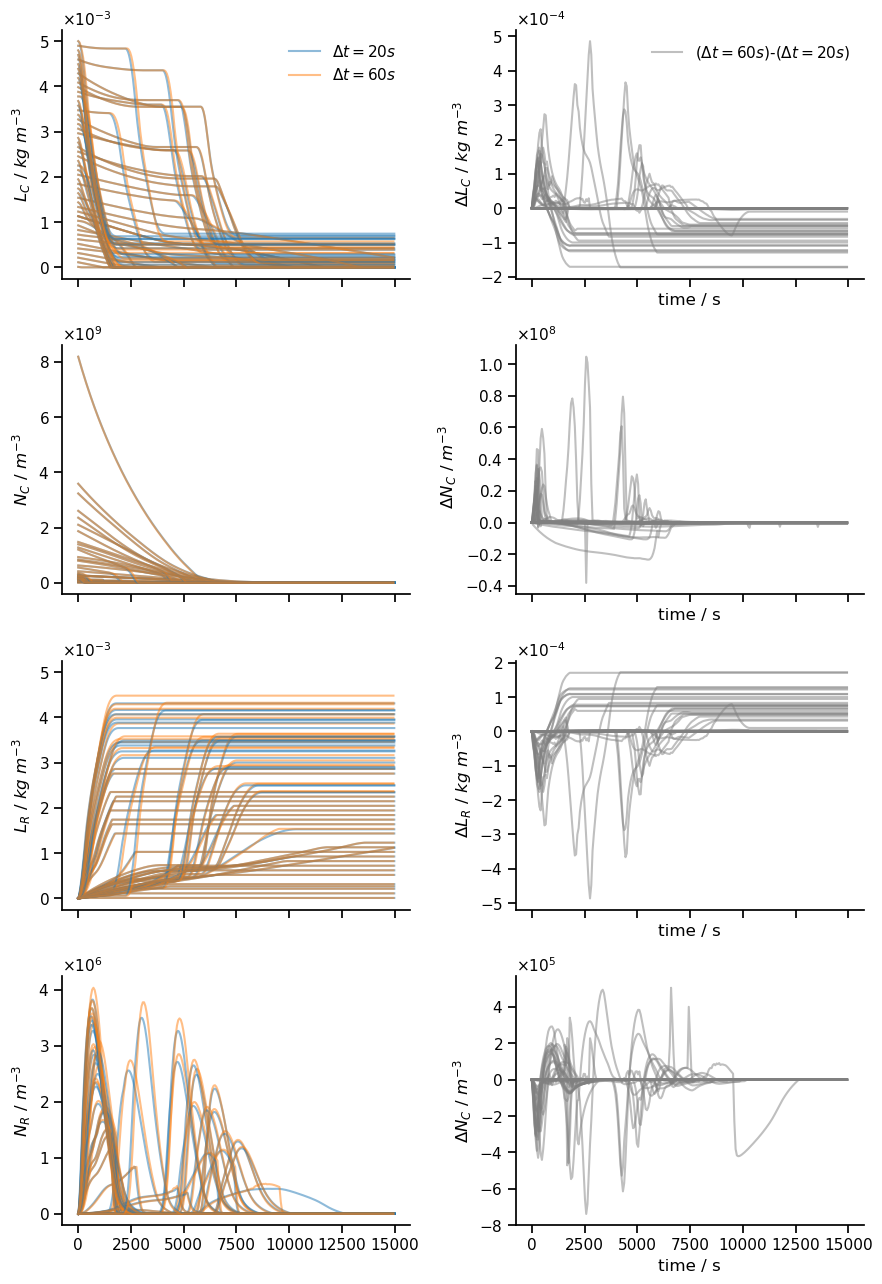

In [16]:
fig, axes = plt.subplots(4,2,figsize=(9,13), sharex=True)

variables = ["$L_C$ / $kg \ m^{-3}$", "$N_C$ / $m^{-3}$", "$L_R$ / $kg \ m^{-3}$", "$N_R$ / $m^{-3}$"]
variables_diff = ["$\Delta L_C$ / $kg \ m^{-3}$", " $\Delta N_C$ / $m^{-3}$", "$\Delta L_R$ / $kg \ m^{-3}$", "$\Delta N_C$ / $m^{-3}$"]

diff = moments_1x60_ens[:, 0:loops,0, :] -  moments_3x20_ens[:, 0:loops*3:3,0, :] 
# plot training regime:

qc_min=0.2e-3
qc_max=2e-3


#first lines:

line_20 = axes[0,0].plot(np.arange(0,loops*3)*20, moments_3x20_ens[0, :loops*3,0, 0], alpha = 0.5, color="tab:blue", label="$\Delta t = 20s$")
line_60 = axes[0,0].plot(np.arange(0,loops)*60, moments_1x60_ens[0, :loops, 0, 0],  alpha = 0.5, color="tab:orange", label="$\Delta t = 60s$")
axes[0,1].plot(np.arange(0,loops)*60, diff[0,:loops,0],  alpha = 0.5, color="grey", label="$(\Delta t = 60s)$-$(\Delta t = 20s)$")


time_3x20 = np.arange(0,loops*3)*20
time_1x60 = np.arange(0,loops)*60



for i in range(4) :
    ax = axes[i,:]
    for j in range(ens) :
        line_20 = ax[0].plot(time_3x20, moments_3x20_ens[j, :loops*3,0, i], alpha = 0.5, color="tab:blue")
        line_60 = ax[0].plot(time_1x60, moments_1x60_ens[j, :loops, 0, i],  alpha = 0.5, color="tab:orange")
        ax[1].plot(np.arange(0,loops)*60, diff[j,:loops,i],  alpha = 0.5, color="grey")
    ax[0].set_ylabel(variables[i])
    ax[1].set_ylabel(variables_diff[i])
    ax[1].set_xlabel("time / s")
    #ax[1].set_ylim(0, np.max(np.concat([moments_3x20_ens[:, :loops*3,0, i].flatten(),moments_1x60_ens[:, :loops, 0, i].flatten()],)))
    sns.despine()

#line_20[0].set_label('3x20s')
#line_60[0].set_label('1x60s')
axes[0,0].legend(frameon=False)
axes[0,1].legend(frameon=False)

axes[2,0].set_ylim(axes[0,0].get_ylim())


from matplotlib.ticker import ScalarFormatter
for ax in axes.flatten():
    formatter = ScalarFormatter(useMathText=True)
    formatter.set_scientific(True)
    formatter.set_powerlimits((-1, 1))  # force sci notation for all magnitudes
    ax.yaxis.set_major_formatter(formatter)

#for ax in axes[1,:] :
#    ax.set_yscale("log")

#axes[0].legend(frameon=False)

plt.tight_layout()

plt.savefig("../plots/offline_SDN_behaviour_random_ensemble.png")

# define 3 samples: in training and two out of training

In [15]:
ens=3

# in training range, representing r=13 micrometers
# out of training range, representing r=7.3 micrometers
# out of training range, representing r=18 micrometers


qc = np.array([1e-3, 1e-3, 2.5e-3])
qnc = np.array([1e8,6e8,1e8])
qr = np.array([0., 0., 0.])
qnr = np.array([0., 0., 0.])

loops = 200

moments_3x20_ens = np.zeros((ens, loops*3+1, 1, 4))
moments_1x60_ens = np.zeros((ens, loops+1, 1, 4))
moments_unconstrained_ens = np.zeros((ens, loops*3+1, 1, 4))

for i in range(ens) :
    moments_idealised_in = [qc[i], qnc[i], qr[i], qnr[i]]
    
    moments_3x20_ens[i,:,:,:] = superdropnet_idealised(model, loops = loops*3,moments_in = moments_idealised_in, apply_thresh=True )
    moments_1x60_ens[i,:,:,:] = superdropnet_idealised(model_60s, loops=loops,moments_in = moments_idealised_in, apply_thresh=True)
    moments_unconstrained_ens[i,:,:,:] = superdropnet_idealised(model_unconstrained, loops=loops*3,moments_in = moments_idealised_in, apply_thresh=True)
    


Include 2moment scheme estimates (calculated with julia package)

In [9]:
import pandas as pd

df_1 = pd.read_csv("warm_rain_moments_1.csv")
df_2 = pd.read_csv("warm_rain_moments_2.csv")
df_3 = pd.read_csv("warm_rain_moments_3.csv")
print(df_1.head())

df_list = [df_1,df_2,df_3]

      t  q_liq         N_liq         q_rai      N_rai
0   0.0  0.001  1.000000e+08  0.000000e+00   0.000000
1  20.0  0.001  9.987913e+07  4.648718e-09  17.879684
2  40.0  0.001  9.975827e+07  9.653246e-09  37.127761
3  60.0  0.001  9.963740e+07  1.490095e-08  57.308515
4  80.0  0.001  9.951654e+07  2.036974e-08  78.325326


/tmp/ipykernel_2272242/2419108720.py:18: RuntimeWarning: invalid value encountered in divide
  cloud_size_3x20 = moments_3x20_ens[:,:,:,0] / moments_3x20_ens[:,:,:,1]
/tmp/ipykernel_2272242/2419108720.py:19: RuntimeWarning: invalid value encountered in divide
  rain_size_3x20 = moments_3x20_ens[:,:,:,2] / moments_3x20_ens[:,:,:,3]
/tmp/ipykernel_2272242/2419108720.py:24: RuntimeWarning: invalid value encountered in divide
  cloud_size_1x60 = moments_1x60_ens[:,:,:,0] / moments_1x60_ens[:,:,:,1]
/tmp/ipykernel_2272242/2419108720.py:25: RuntimeWarning: invalid value encountered in divide
  rain_size_1x60 = moments_1x60_ens[:,:,:,2] / moments_1x60_ens[:,:,:,3]


[<matplotlib.lines.Line2D object at 0x7fd1cffaf690>, <matplotlib.lines.Line2D object at 0x7fd1cfd33550>, <matplotlib.lines.Line2D object at 0x7fd1dc4b4950>]


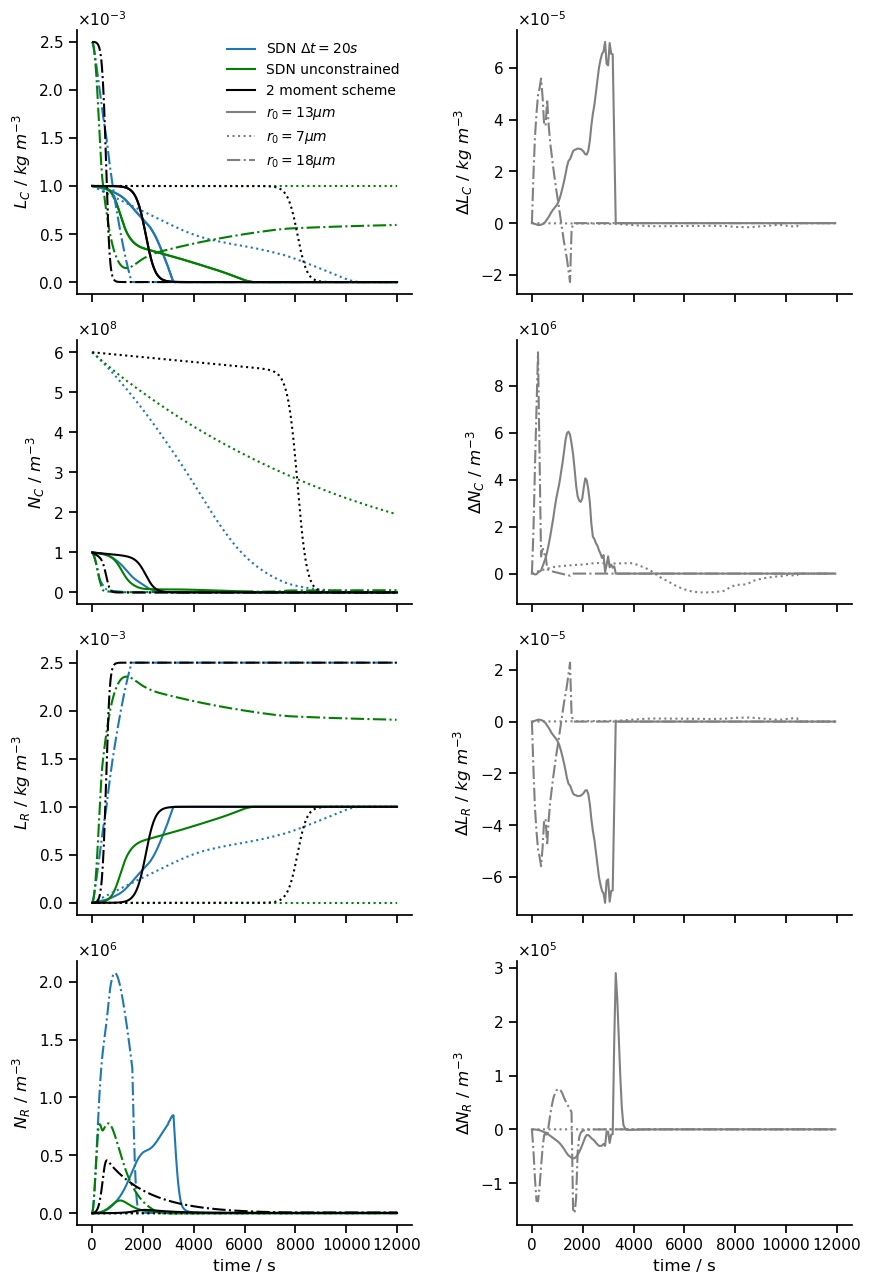

In [19]:
fig, axes = plt.subplots(4,2,figsize=(9,13), sharex=True)

variables = ["$L_C$ / $kg \ m^{-3}$", "$N_C$ / $m^{-3}$", "$L_R$ / $kg \ m^{-3}$", "$N_R$ / $m^{-3}$", "cloud drop size / $kg m^{-3}$", "rain drop size/ $kg m^{-3}$"]
variables_diff = ["$\\Delta L_C$ / $kg \ m^{-3}$", "$\\Delta N_C$ / $m^{-3}$", "$\\Delta L_R$ / $kg \ m^{-3}$", "$\\Delta N_R$ / $m^{-3}$", "cloud drop size difference / $kg m^{-3}$", "rain drop size difference/ $kg m^{-3}$"]


#first lines:

line_20 = axes[0,0].plot(np.arange(0,loops*3)*20, moments_3x20_ens[0, :loops*3,0, 0], color="tab:blue", label="SDN $\Delta t = 20s$")
#line_60 = axes[0,0].plot(np.arange(0,loops)*60, moments_1x60_ens[0, :loops, 0, 0],  color="tab:orange", label="$\Delta t = 60s$")
line_unconstrained = axes[0,0].plot(np.arange(0,loops*3)*20, moments_unconstrained_ens[0, :loops*3, 0, 0],  color="green", label="SDN unconstrained")

line_2mom = axes[0,0].plot(df_1["t"], df_1["q_liq"],  color="black", label="2 moment scheme")

time_3x20 = np.arange(0,loops*3)*20
time_1x60 = np.arange(0,loops)*60

cloud_size_3x20 = moments_3x20_ens[:,:,:,0] / moments_3x20_ens[:,:,:,1]
rain_size_3x20 = moments_3x20_ens[:,:,:,2] / moments_3x20_ens[:,:,:,3]

cloud_size_3x20[cloud_size_3x20 == np.inf] = 0
rain_size_3x20[cloud_size_3x20 == np.inf] = 0

cloud_size_1x60 = moments_1x60_ens[:,:,:,0] / moments_1x60_ens[:,:,:,1]
rain_size_1x60 = moments_1x60_ens[:,:,:,2] / moments_1x60_ens[:,:,:,3]

cloud_size_1x60[cloud_size_1x60 == np.inf] = 0
rain_size_1x60[cloud_size_1x60 == np.inf] = 0

moments_3x20_plot = np.concatenate([moments_3x20_ens,np.expand_dims(cloud_size_3x20,-1),np.expand_dims(rain_size_3x20,-1)],axis=3)
moments_1x60_plot = np.concatenate([moments_1x60_ens,np.expand_dims(cloud_size_1x60,-1),np.expand_dims(rain_size_1x60,-1)],axis=3)

diff = moments_1x60_plot[:, 0:loops,0, :] -  moments_3x20_plot[:, 0:loops*3:3,0, :] 

ls=["-",":","-."]


for i in range(4) :
    ax = axes[i,:]
    for j in range(ens) :
        line_20 = ax[0].plot(time_3x20, moments_3x20_plot[j, :loops*3,0, i],  color="tab:blue", linestyle=ls[j])
        #line_60 = ax[0].plot(time_1x60, moments_1x60_plot[j, :loops, 0, i],   color="tab:orange", linestyle=ls[j])
        line_unconstrained = ax[0].plot(time_3x20, moments_unconstrained_ens[j, :loops*3, 0, i],  color="green", linestyle=ls[j])
        ax[1].plot(np.arange(0,loops)*60, diff[j,:loops,i],  color="grey", linestyle=ls[j])
    ax[0].set_ylabel(variables[i])
    ax[1].set_ylabel(variables_diff[i])
    sns.despine()

axes[3,0].set_xlabel("time / s")
axes[3,1].set_xlabel("time / s")

for j,df in enumerate(df_list) :
    axes[0,0].plot(df_1["t"], df["q_liq"],   color="black",  linestyle=ls[j])
    axes[1,0].plot(df_1["t"], df["N_liq"],   color="black", linestyle=ls[j])
    axes[2,0].plot(df_1["t"], df["q_rai"],   color="black", linestyle=ls[j])
    axes[3,0].plot(df_1["t"], df["N_rai"],   color="black", linestyle=ls[j])

#line_20[0].set_label('3x20s')
#line_60[0].set_label('1x60s')
#axes[0,0].legend(frameon=False)

handles, labels = axes[0,0].get_legend_handles_labels()

print(handles)

from matplotlib.ticker import ScalarFormatter
for ax in axes.flatten():
    formatter = ScalarFormatter(useMathText=True)
    formatter.set_scientific(True)
    formatter.set_powerlimits((-1, 1))  # force sci notation for all magnitudes
    ax.yaxis.set_major_formatter(formatter)


from matplotlib.lines import Line2D

labels_ls = ["$r_0=13 \mu m$", "$r_0=7 \mu m$", "$r_0=18 \mu m$"]

handles_ls = [
    Line2D([0], [0], color="grey", ls=l)
    for l in ls
]

handles += handles_ls
labels += labels_ls

axes[0,0].legend(handles, labels, loc="best", frameon=False, fontsize='small')


#for ax in axes[1,:] :
#    ax.set_yscale("log")

#axes[0].legend(frameon=False)

plt.tight_layout()

plt.savefig("../plots/offline_SDN_behaviour.png")